<a href="https://colab.research.google.com/github/RobertoSonzini/NAML_project/blob/main/Progetto_NAML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Progetto NAML**

## **Project Overview**

SPIEGAZIONE CONCETTI LSTM, GAN e PRINCIPI

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import torch
from torch import nn
import math

## **Dataset study**

DOBBIAMO PULIRE IL DATASET: TOGLIERE NULLI (nel metodo per ottenere un sotto-dataset l'ho già implementato) E VEDERE SE ABBIAMO OUTSIDERS (NEL CASO POSSIMAO VEDERE COSA SUCCEDE E SE HANNO IMPATTO)

In [1]:
!pip install tensorflow

In [4]:
file_path = '/content/drive/MyDrive/ProgettoNAML/all_stocks_5yr.csv'
drive.mount('/content/drive')

df = pd.read_csv(file_path)
df.head()

%matplotlib inline

from datetime import datetime

df.info()
df

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL
...,...,...,...,...,...,...,...
619035,2018-02-01,76.84,78.27,76.69,77.82,2982259,ZTS
619036,2018-02-02,77.53,78.12,76.73,76.78,2595187,ZTS
619037,2018-02-05,76.64,76.92,73.18,73.83,2962031,ZTS
619038,2018-02-06,72.74,74.56,72.13,73.27,4924323,ZTS


In [5]:
latest_date = pd.to_datetime(df['date']).max()

one_year_before = latest_date - pd.DateOffset(years=1)

date_series = pd.to_datetime(df['date'])
mask = (date_series >= one_year_before) & (date_series <= latest_date) & (df['Name'] == 'AAPL')

filtered_df = df[mask]
filtered_df['date'] = pd.to_datetime(filtered_df['date'])

/tmp/ipython-input-5-1817002058.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['date'] = pd.to_datetime(filtered_df['date'])


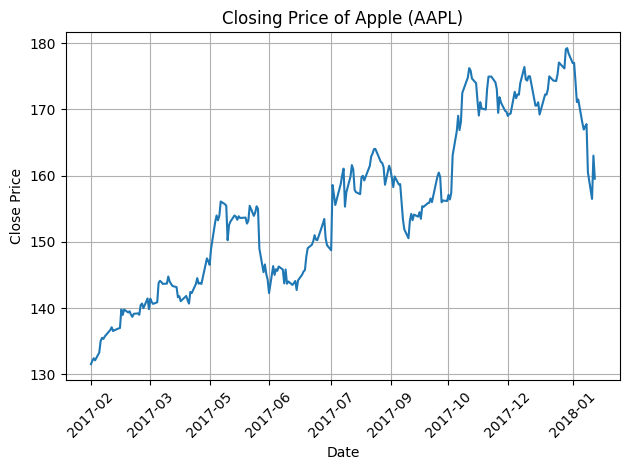

In [6]:
plt.plot(filtered_df['date'], filtered_df['close'])
plt.ylabel('Close Price')
plt.xlabel('Date')
plt.title("Closing Price of Apple (AAPL)")

# Mostra solo una data ogni 30 giorni (puoi cambiare questo intervallo)
step = 30

# Usa xticks per visualizzare solo alcune date
plt.xticks(ticks=filtered_df['date'][::step], labels=filtered_df['date'].dt.strftime('%Y-%m')[::step], rotation=45)

plt.grid(True)
plt.tight_layout()

plt.show()

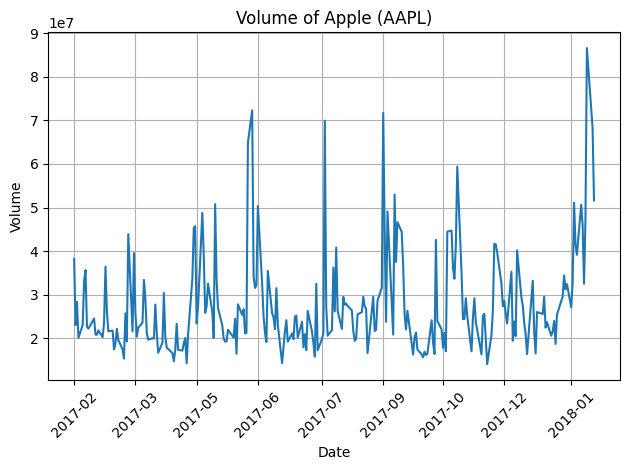

In [7]:
plt.plot(filtered_df['date'], filtered_df['volume'])
plt.ylabel('Volume')
plt.xlabel('Date')
plt.title("Volume of Apple (AAPL)")

# Mostra solo una data ogni 30 giorni (puoi cambiare questo intervallo)
step = 30

# Usa xticks per visualizzare solo alcune date
plt.xticks(ticks=filtered_df['date'][::step], labels=filtered_df['date'].dt.strftime('%Y-%m')[::step], rotation=45)

plt.grid(True)
plt.tight_layout()

plt.show()

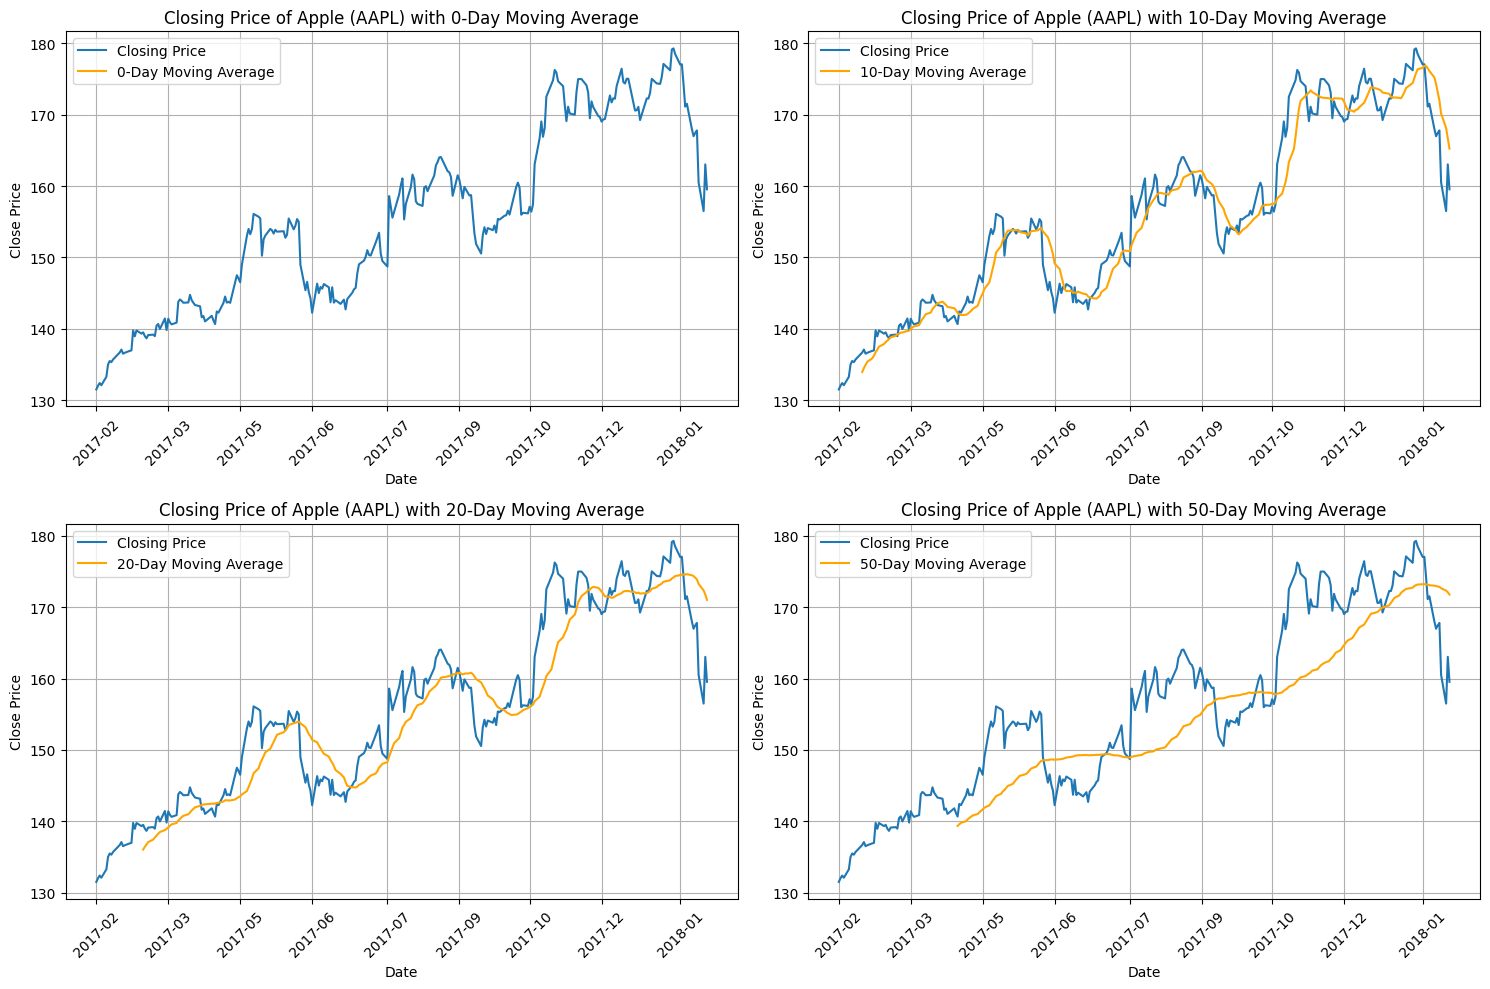

In [8]:
import matplotlib.pyplot as plt

ma_day = [0, 10, 20, 50]  # Diversi periodi per la media mobile
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))  # Creazione di una figura 2x2

# Ciclo per calcolare e tracciare la media mobile per ciascun valore di 'ma'
for i, ma in enumerate(ma_day):
    # Crea una copia del dataset per ogni 'ma'
    df_copy = filtered_df.copy()
    df_copy['ma_close'] = df_copy['close'].rolling(ma).mean()

    # Seleziona l'asse per il grafico
    ax = axes[i // 2, i % 2]  # Seleziona l'asse giusto (2 righe, 2 colonne)

    # Plot del prezzo di chiusura
    ax.plot(df_copy['date'], df_copy['close'], label='Closing Price')

    # Plot della media mobile
    ax.plot(df_copy['date'], df_copy['ma_close'], label=f'{ma}-Day Moving Average', color='orange')

    # Aggiungi etichette, titolo e legenda
    ax.set_ylabel('Close Price')
    ax.set_xlabel('Date')
    ax.set_title(f"Closing Price of Apple (AAPL) with {ma}-Day Moving Average")
    ax.legend()

    # Mostra solo alcune date sull'asse X
    step = 30
    ax.set_xticks(df_copy['date'][::step])
    ax.set_xticklabels(df_copy['date'].dt.strftime('%Y-%m')[::step], rotation=45)

    # Mostra la griglia
    ax.grid(True)

# Ottimizza la visualizzazione
plt.tight_layout()
plt.show()

## **Network setup**

### **Training dataset setup**

In [ ]:
# Facciamo una split del dataset per avere training, validation (vediamo poi se e come usarlo) e test set.
'''
  1. decidere che dati utilizzare
  2. vettore 'input data' usato dal paper: [high_price, low_price, open_price, close_price, volume, turnover_rate, Ma(5)]
'''

In [9]:
df.head()

,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


#### **Step 1) select a single company and complete the dataset**

*We filter our dataset to have data of the company "APPLE" and we compute the MA(5)*

In [38]:
def sort_by_date(df):
  return df.sort_values(by='date')

In [39]:
def get_dataframe(df, company_names, moving_average=5):
    input_data_labels = ['high', 'low', 'open', 'close', 'volume', 'ma5']

    mask = df['Name'].isin(company_names)
    df_company = df.loc[mask].copy()

    df_company['ma5'] = df_company['close'].rolling(moving_average).mean()

    df_company = df_company.dropna()

    df_company = sort_by_date(df_company)

    return df_company[input_data_labels]

In [40]:
df_apple = get_dataframe(df, ['AAPL'])
df_apple.head()

,high,low,open,close,volume,ma5
1263,67.3771,66.2885,66.3599,66.6556,88809154,67.32592
1264,67.1656,65.7028,66.9785,65.7371,97924631,66.90250
1265,66.1042,64.8356,65.8714,65.7128,108854046,66.33278
1266,65.3842,64.1142,65.3842,64.1214,118891367,65.78850
1267,64.1671,63.2599,63.7142,63.7228,111596821,65.18994


In [41]:
df_apple.shape[0]

1255

##### **Analysis of dataset size per individual company**

In [42]:
company_sizes = {}
companies = df['Name'].unique()

for company in companies:
  df_company = get_dataframe(df, [company])
  company_sizes[company] = df_company.shape[0]

In [43]:
key_max = max(company_sizes, key=company_sizes.get)
val_max = company_sizes[key_max]

key_min = min(company_sizes, key=company_sizes.get)
val_min = company_sizes[key_min]

# Output
print(f"MAX → {key_max}: {val_max}")
print(f"MIN → {key_min}: {val_min}")

MAX → AAL: 1255
MIN → APTV: 40


#### **Splitting the dataset**

In [45]:
company = ['AAPL']
df_company = get_dataframe(df, company)

In [47]:
length = len(df)
split_idx = int(length * 0.8)

df_company_train = df.iloc[:split_idx]
df_company_test = df.iloc[split_idx:]

### **Discriminator and Generator**

In [52]:
class Discriminator(nn.Module):
  '''
    From paper:
      Here, we choose an MLP as our discriminator with three hidden layers h1,h2,h3 including 72, 100, 10 neurons, respectively.
      The Leaky ReLU is used as the activation function among the hidden layers and the sigmoid function is used in the output layer.

      Cose da notare / considerare:
        - Dato che stiamo usando un MLP, vuoi un input a forma di vettore, però nel paper viene usato un input che prevede più samples.
          In particolare costruisce una matrice X formata da (t + 1) time steps (presi dai dati reali).
          I primi t valori saranno presi dal dattaset, mentre l'ultimo verrà o generato dal generatore, oppure preso anch'esso dal dataset reale.

        - A seguito di quanto detto nel punto prima, sarà anche da considerare l'ampiezza dell'intervallo di time steps come hyperparameter.

        - Andrà anche considerato che nel nostrto dataset, non abbiamo un dato per ogni giorno specifico.
          Potrebbe essere sensato kl non considare questo aspetto poichè alla fine non poniamo le date come un input utile.
          Se volessimo però avere una predizione che considera la data, cioè vogliamo considerare anche che c'è una dipendenza dagli effetivi giorni che separano un sample al tempo t e al tempo t+1,
            dovremmo intervenire in qualche modo.
          (da notare che attualmente le moving average non tengono conto di questo)

        - Come gestiamo la differenza dimensionale tra gli input?
          Soluzione 1: Usiamo un reshape che rende unidimensionale la matrice concatenando un sample dietro l'altro
  '''

  '''
    t_input: la size già calcolata come t+1.
    t_features: è il numero di features per ogni sample.
  '''
  def __init__(self, t_input, n_features):
    super().__init__()
    self.n_features = n_features
    self.t_input = t_input
    self.model = nn.Sequential(

    # The input is two-dimensional (perchè ho un MLP), and the first hidden layer is composed of 256 neurons with ReLU activation.
    # The second and third hidden layers are composed of 128 and 64 neurons, respectively, with ReLU activation.
    # The output is composed of a single neuron with sigmoidal activation to represent a probability. <---
    # After the first, second, and third hidden layers, you use dropout to avoid overfitting.

      nn.Linear(self.n_features * self.t_input, 72),
      nn.ReLU(),
      nn.Dropout(0.3),
      nn.Linear(72, 100),
      nn.ReLU(),
      nn.Dropout(0.3),
      nn.Linear(100, 10),
      nn.ReLU(),
      nn.Dropout(0.3),
      nn.Linear(10, 1),
      nn.Sigmoid(),
    )

    # You use .forward() to describe how the output of the model is calculated.
    # Here, x represents the input of the model, which is a two-dimensional tensor.
    # In this implementation, the output is obtained by feeding the input x to the model you’ve defined without any other processing.

    def forward(self, X):
      X_flat = X.view(-1)
      output = self.model(X_flat)
      return output